# Preliminary SAE results: reconstruction, sparsity, and dictionary coverage

This comparison asks how two finalized sparse autoencoders (SAEs) balance **reconstruction quality**, **sparsity per example**, and **dictionary coverage across validation examples**. All four metrics come from evaluation of each model's saved best checkpoint on the same validation activation data. These are descriptive results for these two checkpoints, not averages across repeated seeds.

Both models use layer 33 activations with 2,560 input dimensions and a dictionary of 12,888 latent features. Inputs are divided by a single RMS scale computed from training activations; that scale is reused for validation. The table compares reconstruction error in these normalized units.

## Models and saved sources

- **TopK + AuxK:** TopK sparsity with `top_k = 128`, plus a training-only auxiliary reconstruction objective with `aux_coefficient = 0.0078125`. AuxK targets eligible inactive features during training. The finalized model is trial 3 of the AuxK diagnostics study; its best checkpoint is epoch 179.
  - Run: `results/sae/musique/runs/layer_33/20261013T233444019723Z-e5943205b957/`
- **L1:** an L1 penalty on latent activations with `sparsity_coefficient = 5.0`. Its number of positive activations varies by example. The finalized model is trial 3 of the L1 refinement study; its best checkpoint is epoch 111. This was the coverage-oriented choice; the study's automatic activity-budget selection suggested trial 7 instead.
  - Run: `results/sae/musique/runs/layer_33/20261014T161949048498Z-edfc89a42125/`

The code reads `config.json` for model settings, `manifest.json` for validation-data provenance, and `history.json` → `summary` → `frozen_checkpoint_metrics` → `validation` for metrics. These frozen metrics describe the checkpoint used for inference; the last training-history row need not describe that checkpoint.

## What each metric means

| Metric | Definition | Interpretation |
| --- | --- | --- |
| Reconstruction MSE | Mean squared difference between the original and reconstructed activations, averaged over validation examples and input dimensions, in RMS-normalized units. Saved as `rec_loss`. | Lower means a more faithful reconstruction. We compare reconstruction alone because the models' total losses contain different penalties. |
| Variance explained | $1 - \mathrm{SSE}_{\mathrm{reconstruction}} / \mathrm{SSE}_{\mathrm{baseline}}$, where the baseline predicts the **training-mean activation vector** for each validation example. Saved as `variance_explained`. | Higher means more improvement over this constant baseline; 100% is perfect reconstruction, 0% matches the baseline, and negative values are worse. |
| Mean active features per example | Average count of latent features with a **positive** activation on a validation example. Saved as `mean_active_features`. | Lower means a sparser representation per example. This is an observed count, not simply the configured TopK value. |
| Dictionary features active at least once on validation | $100\times(1-\mathrm{inactive\_feature\_fraction})$. A feature counts as used if it has a positive activation on at least one validation example. | Higher means broader coverage of the dictionary across this split. It does not mean more features are active simultaneously. |

## How to interpret the comparison

For these checkpoints, TopK + AuxK reconstructs better (MSE approximately 0.0434 versus 0.0589; variance explained 83.2% versus 77.2%). L1 activates fewer features per example (approximately 66 versus 128) while using more of the dictionary across validation examples (97.3% versus 24.2%). Sparse individual representations and broad aggregate dictionary coverage can therefore coexist.

This tradeoff motivates carrying both models into downstream experiments. Coverage does **not** establish semantic interpretability, useful causal features, or successful interventions. A feature never observed on validation is also not necessarily permanently dead: split-level inactivity differs from the training-time persistent-inactivity diagnostic. The comparison does not isolate the effect of one hyperparameter, since these configurations differ in multiple settings.

## Reproduce the table

Run the following cells from either the repository root or the `cookbooks` directory. No training or checkpoint loading is required. Run IDs are explicit so future experiments do not silently change which models are compared. The loader checks that the recorded validation hashes, layer, dimensions, and training RMS scale agree. Values retain full precision in `comparison_numeric`; only the displayed table is rounded.


In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

# Locate the repository without depending on the notebook's working directory.
REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "results/sae/musique/runs/layer_33").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the project repository.")

RUN_IDS = {
    "TopK + AuxK": "20261013T233444019723Z-e5943205b957",
    "L1": "20261014T161949048498Z-edfc89a42125",
}

def read_json(path):
    with path.open(encoding="utf-8") as handle:
        return json.load(handle)

runs = {}
for label, run_id in RUN_IDS.items():
    directory = REPO_ROOT / "results/sae/musique/runs/layer_33" / run_id
    config = read_json(directory / "config.json")
    manifest = read_json(directory / "manifest.json")
    history = read_json(directory / "history.json")
    if manifest["status"] != "completed":
        raise ValueError(f"{label}: expected a completed run.")
    runs[label] = {
        "config": config,
        "manifest": manifest,
        "summary": history["summary"],
        "metrics": history["summary"]["frozen_checkpoint_metrics"]["validation"],
    }

validation_hashes = {
    run["manifest"]["activation_files"]["validation"]["sha256"]
    for run in runs.values()
}
if len(validation_hashes) != 1 or not all(validation_hashes):
    raise ValueError("The runs do not record matching validation activation hashes.")
for field in ("layer", "input_dim", "latent_dim", "activation_rms_scale"):
    if len({run["config"][field] for run in runs.values()}) != 1:
        raise ValueError(f"The runs differ in {field}; review comparability first.")


In [2]:
# Percent-valued metrics stay as fractions here to retain their natural units.
comparison_numeric = pd.DataFrame({
    label: {
        "Reconstruction MSE": run["metrics"]["rec_loss"],
        "Variance explained": run["metrics"]["variance_explained"],
        "Mean active features per example": run["metrics"]["mean_active_features"],
        "Dictionary features active at least once on validation": (
            1.0 - run["metrics"]["inactive_feature_fraction"]
        ),
    }
    for label, run in runs.items()
})
comparison_numeric.index.name = "Metric"

row_formats = {
    "Reconstruction MSE": ".4f",
    "Variance explained": ".1%",
    "Mean active features per example": ".1f",
    "Dictionary features active at least once on validation": ".1%",
}
comparison_table = pd.DataFrame(
    {
        label: [format(comparison_numeric.loc[metric, label], row_formats[metric])
                for metric in comparison_numeric.index]
        for label in comparison_numeric.columns
    },
    index=comparison_numeric.index,
)
display(comparison_table)


,TopK + AuxK,L1
Metric,,
Reconstruction MSE,0.0434,0.0589
Variance explained,83.2%,77.2%
Mean active features per example,128.0,66.0
Dictionary features active at least once on validation,24.2%,97.3%


## Export the comparison table for slides

Save the displayed table to `reports/figures/sae_preliminary_results/sae_validation_comparison.svg`. This keeps presentation figures together under `reports`, separate from experiment artifacts. The directory is created automatically, and rerunning the cell updates the same SVG. The export uses the values in `comparison_table`, with a title and validation-checkpoint caption. SVG preserves sharp text and lines when resized; text is kept editable for slide or vector editors.


In [3]:
import matplotlib.pyplot as plt

FIGURE_DIR = REPO_ROOT / "reports" / "figures" / "sae_preliminary_results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
svg_path = FIGURE_DIR / "sae_validation_comparison.svg"

# Keep SVG labels as editable text rather than converting them to paths.
with plt.rc_context({"svg.fonttype": "none", "font.family": "DejaVu Sans"}):
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.axis("off")
    fig.suptitle(
        "SAE validation comparison", x=0.06, y=0.96,
        ha="left", fontsize=18, fontweight="bold", color="#172B4D",
    )
    rows = [
        [metric, *comparison_table.loc[metric].tolist()]
        for metric in comparison_table.index
    ]
    table = ax.table(
        cellText=rows,
        colLabels=["Metric", *comparison_table.columns.tolist()],
        colWidths=[0.70, 0.15, 0.15],
        cellLoc="center", bbox=[0, 0.13, 1, 0.83],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    for (row, column), cell in table.get_celld().items():
        cell.set_edgecolor("#D9E2EC")
        cell.set_linewidth(0.7)
        cell.PAD = 0.025
        if row == 0:
            cell.set_facecolor("#172B4D")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor("#F0F4F8" if row % 2 else "white")
            cell.set_text_props(color="#172B4D")
        if column == 0:
            cell.set_text_props(ha="left")
    fig.text(
        0.06, 0.055,
        "Saved best checkpoints · Layer 33 · Validation split · 12,888 latent features",
        fontsize=10, color="#52606D",
    )
    fig.subplots_adjust(left=0.06, right=0.97, top=0.84, bottom=0.12)
    fig.savefig(svg_path, format="svg", bbox_inches="tight", facecolor="white")
    plt.close(fig)

print(f"Saved SVG: {svg_path.relative_to(REPO_ROOT)}")


Saved SVG: reports/figures/sae_preliminary_results/sae_validation_comparison.svg


## Hyperparameter sweeps: selecting tradeoffs across two sparsity strategies

We explored **TopK** and **L1** sparsity, sweeping their hyperparameters and choosing representative models based on three priorities: reconstruction accuracy, sparsity per example, and dictionary usage across validation examples. AuxK is a training variation within the TopK family.

The figure uses one point per completed trial from four completed studies: the initial TopK sweep, TopK + AuxK diagnostics, the coarse L1 sweep, and L1 refinement. The inventory below records included and excluded studies. The two interrupted studies are excluded from this main presentation comparison, including their completed trials, to show complete search grids. This is a declared scope choice, not a filter on metric quality. The study IDs are fixed so future runs do not silently change this figure.

### Reading the figure

- **Horizontal position:** mean positive latent activations per validation example; farther left is sparser. The axis is logarithmic to accommodate a wide range of activity.
- **Vertical position:** validation variance explained relative to the training-mean baseline; higher is better reconstruction. Negative values mean worse reconstruction than that baseline.
- **Color:** percentage of dictionary features active at least once on validation, using a shared 0–100% scale; brighter colors mean broader coverage.
- **Shape:** circles are TopK (including AuxK); triangles are L1.
- **Black outlines and labels:** the source tuning trials of the two finalized models above. These are manual choices of useful tradeoffs, not claims of a single universal optimum.

The left panel shows the entire included search, including poorly reconstructing L1 configurations. The right panel zooms to trials with nonnegative variance explained; its title states how many points fall outside the view. Desirable tradeoffs are toward the upper left with high dictionary coverage, but no single point necessarily optimizes all three criteria.

### Comparability and selection

The loader checks train/validation activation hashes, layer, input and dictionary dimensions, normalization, seed, and configured epoch budget. It uses the resolved trial configs (the sweep CSV's input-dimension defaults can be stale) and frozen validation checkpoint metrics. All included trials have a 200-epoch maximum budget; actual training lengths vary with early stopping. Learning rates, initialization, auxiliary objectives, stopping settings, and code versions may differ across studies, so this is an exploratory comparison, not a controlled ablation or a repeated-seed estimate.

The highlighted trials are recovered from the published runs' provenance. Trial metrics remain distinct from finalized metrics even when they agree. No test results enter this plot or selection rationale. The accompanying CSV preserves trial IDs, parameters, training lengths, code versions, and metrics for tracing individual points.


In [4]:
import numpy as np

TUNING_ROOT = REPO_ROOT / "results/sae/musique/tuning/layer_33"
STUDY_LABELS = {
    "20261012T222316667696Z-941bd68388fa": "Initial TopK sweep",
    "20261013T173330494845Z-e5943205b957": "TopK + AuxK diagnostics",
    "20261013T234044861337Z-35e93bdfd4fe": "Coarse L1 sweep",
    "20261014T131200337301Z-edfc89a42125": "L1 refinement",
}
TABLE_DIR = REPO_ROOT / "reports/tables/sae_preliminary_results"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Link the highlighted points to the finalized models, rather than selecting
# a winner from test metrics or assuming the automatic suggestion was used.
chosen_trials = {}
for label, run in runs.items():
    origin = run["config"]["tuning"]
    chosen_trials[(Path(origin["study_directory"]).name, int(origin["trial_id"]))] = label

reference = runs["TopK + AuxK"]
reference_config = reference["config"]
reference_hashes = {
    split: reference["manifest"]["activation_files"][split]["sha256"]
    for split in ("train", "validation")
}
comparison_fields = (
    "layer", "input_dim", "latent_dim", "activation_rms_scale",
    "input_normalization", "reconstruction_loss", "seed", "epochs",
)
trial_records, inventory_records = [], []
for directory in sorted(TUNING_ROOT.iterdir()):
    if not directory.is_dir() or not (directory / "trials.csv").exists():
        continue
    manifest = read_json(directory / "manifest.json")
    rows = pd.read_csv(directory / "trials.csv")
    included = directory.name in STUDY_LABELS
    if included and manifest["status"] != "completed":
        raise ValueError(f"Expected a completed study: {directory.name}")
    inventory_records.append({
        "Study": STUDY_LABELS.get(directory.name, directory.name),
        "Status": manifest["status"],
        "Completed trials": int(rows["status"].eq("completed").sum()),
        "Listed trials": len(rows),
        "Included": included,
        "Reason": "Completed presentation sweep" if included else (
            "Interrupted study" if manifest["status"] != "completed" else "Outside fixed study list"
        ),
        "study_id": directory.name,
    })
    if not included:
        continue
    for split, expected_hash in reference_hashes.items():
        if manifest["activation_files"][split]["sha256"] != expected_hash:
            raise ValueError(f"Activation mismatch: {directory.name}, {split}")
    for row in rows.loc[rows["status"].eq("completed")].to_dict("records"):
        trial_id = int(row["trial_id"])
        trial_dir = directory / "trials" / f"trial_{trial_id:04d}"
        config = read_json(trial_dir / "config.json")
        trial_manifest = read_json(trial_dir / "manifest.json")
        if trial_manifest["status"] != "completed":
            raise ValueError(f"Trial status mismatch: {trial_dir}")
        for split, expected_hash in reference_hashes.items():
            if trial_manifest["activation_files"][split]["sha256"] != expected_hash:
                raise ValueError(f"Trial activation mismatch: {trial_dir}, {split}")
        for field in comparison_fields:
            if config[field] != reference_config[field]:
                raise ValueError(f"Incompatible {field}: {trial_dir}")
        summary = read_json(trial_dir / "history.json")["summary"]
        metrics = summary["frozen_checkpoint_metrics"]["validation"]
        for csv_key, metric_key in (
            ("val_rec_loss", "rec_loss"),
            ("val_variance_explained", "variance_explained"),
            ("val_mean_active_features", "mean_active_features"),
            ("val_inactive_feature_fraction", "inactive_feature_fraction"),
        ):
            if not np.isclose(float(row[csv_key]), metrics[metric_key], rtol=1e-6, atol=1e-9):
                raise ValueError(f"CSV/checkpoint metric mismatch: {trial_dir}, {metric_key}")
        record = {
            "study_id": directory.name, "study": STUDY_LABELS[directory.name],
            "trial_id": trial_id,
            "strategy": {"topk": "TopK", "l1": "L1"}[config["sparsity_mode"]],
            "selected_model": chosen_trials.get((directory.name, trial_id), ""),
            "reconstruction_mse": metrics["rec_loss"],
            "variance_explained_pct": 100 * metrics["variance_explained"],
            "mean_active_features": metrics["mean_active_features"],
            "dictionary_usage_pct": 100 * (1 - metrics["inactive_feature_fraction"]),
            "best_epoch": summary["best_epoch"],
            "epochs_completed": summary["epochs_completed"],
            "git_commit": trial_manifest["git_commit"],
            "trial_directory": str(trial_dir.relative_to(REPO_ROOT)),
        }
        for field in ("top_k", "sparsity_coefficient", "aux_coefficient", "lr", "seed",
                      "epochs", "tied_initialization", "early_stopping_min_delta"):
            record[field] = config.get(field)
        trial_records.append(record)

sweep_trials = pd.DataFrame(trial_records)
study_inventory = pd.DataFrame(inventory_records)
if set(sweep_trials.loc[sweep_trials["selected_model"].ne(""), "selected_model"]) != set(RUN_IDS):
    raise ValueError("Could not locate both selected source trials.")
metric_columns = ["reconstruction_mse", "variance_explained_pct",
                  "mean_active_features", "dictionary_usage_pct"]
if not np.isfinite(sweep_trials[metric_columns].to_numpy()).all():
    raise ValueError("Nonfinite sweep metrics.")
if not sweep_trials["mean_active_features"].gt(0).all():
    raise ValueError("Log-scale plot requires positive mean activity.")
if not sweep_trials["dictionary_usage_pct"].between(0, 100).all():
    raise ValueError("Dictionary usage must be a percentage between 0 and 100.")
sweep_trials.to_csv(TABLE_DIR / "sae_sweep_trials.csv", index=False)
study_inventory.to_csv(TABLE_DIR / "sae_sweep_inventory.csv", index=False)
display(study_inventory.drop(columns="study_id"))
print(f"Plotting {len(sweep_trials)} trials from {len(STUDY_LABELS)} completed studies.")


,Study,Status,Completed trials,Listed trials,Included,Reason
0,Initial TopK sweep,completed,12,12,True,Completed presentation sweep
1,20261013T142312360355Z-272aaa1bbfea,failed,2,8,False,Interrupted study
2,20261013T155904522802Z-a24620ad82c2,failed,2,4,False,Interrupted study
3,TopK + AuxK diagnostics,completed,8,8,True,Completed presentation sweep
4,Coarse L1 sweep,completed,15,15,True,Completed presentation sweep
5,L1 refinement,completed,8,8,True,Completed presentation sweep


Plotting 43 trials from 4 completed studies.


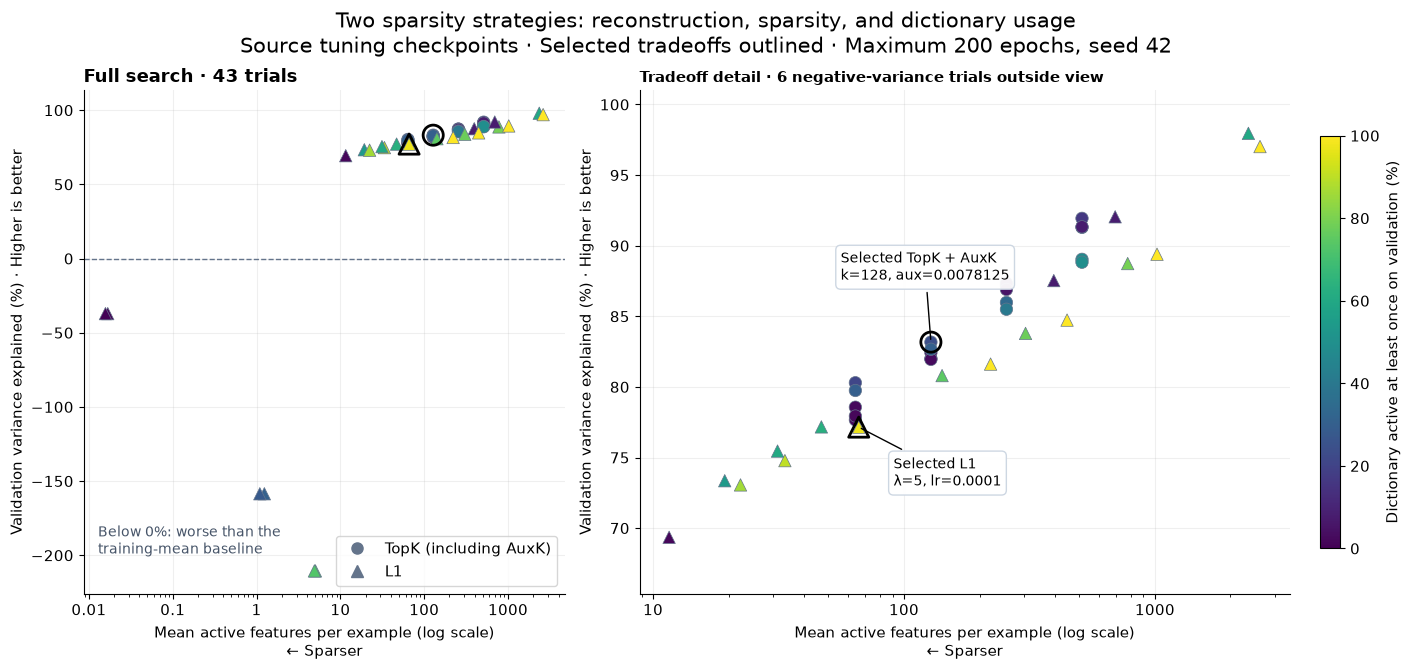

In [5]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator

markers = {"TopK": "o", "L1": "^"}
color_scale = Normalize(vmin=0, vmax=100)
zoom_trials = sweep_trials.loc[sweep_trials["variance_explained_pct"].ge(0)]
excluded_from_zoom = len(sweep_trials) - len(zoom_trials)

with plt.rc_context({"svg.fonttype": "none", "font.family": "DejaVu Sans", "font.size": 11}):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.6), layout="constrained",
                             gridspec_kw={"width_ratios": [1, 1.35]})
    for ax, data in zip(axes, (sweep_trials, zoom_trials)):
        for strategy, marker in markers.items():
            subset = data.loc[data["strategy"].eq(strategy)]
            ax.scatter(
                subset["mean_active_features"], subset["variance_explained_pct"],
                c=subset["dictionary_usage_pct"], cmap="viridis", norm=color_scale,
                marker=marker, s=80, edgecolors="#64748B", linewidths=0.5, zorder=3,
            )
        for row in data.loc[data["selected_model"].ne("")].itertuples():
            ax.scatter(row.mean_active_features, row.variance_explained_pct,
                       marker=markers[row.strategy], s=210, facecolors="none",
                       edgecolors="black", linewidths=2, zorder=5)
        ax.set_xscale("log")
        ax.xaxis.set_major_locator(LogLocator(base=10))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
        ax.set_xlabel("Mean active features per example (log scale)\n← Sparser")
        ax.set_ylabel("Validation variance explained (%) · Higher is better")
        ax.grid(True, alpha=0.2, zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_title(f"Full search · {len(sweep_trials)} trials", loc="left", fontweight="bold")
    axes[0].axhline(0, color="#64748B", linestyle="--", linewidth=1)
    axes[0].text(0.03, 0.08, "Below 0%: worse than the\ntraining-mean baseline",
                 transform=axes[0].transAxes, fontsize=10, color="#475569")
    axes[1].set_title(
        f"Tradeoff detail · {excluded_from_zoom} negative-variance trials outside view",
        loc="left", fontsize=11, fontweight="bold",
    )
    axes[1].set_ylim(zoom_trials["variance_explained_pct"].min() - 4, 101)
    for row in zoom_trials.loc[zoom_trials["selected_model"].ne("")].itertuples():
        label = (f"Selected TopK + AuxK\nk={int(row.top_k)}, aux={row.aux_coefficient:g}"
                 if row.strategy == "TopK" else
                 f"Selected L1\nλ={row.sparsity_coefficient:g}, lr={row.lr:g}")
        offset = (-65, 45) if row.strategy == "TopK" else (25, -42)
        axes[1].annotate(
            label, (row.mean_active_features, row.variance_explained_pct),
            xytext=offset, textcoords="offset points", fontsize=10,
            bbox={"boxstyle": "round,pad=0.35", "fc": "white", "ec": "#CBD5E1", "alpha": 0.95},
            arrowprops={"arrowstyle": "-", "color": "black"}, zorder=6,
        )
    handles = [Line2D([], [], linestyle="", marker=marker, color="#64748B", markersize=8,
                       label=f"{strategy} (including AuxK)" if strategy == "TopK" else strategy)
               for strategy, marker in markers.items()]
    axes[0].legend(handles=handles, loc="lower right", frameon=True)
    colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=color_scale, cmap="viridis"),
                            ax=axes, shrink=0.82, pad=0.025)
    colorbar.set_label("Dictionary active at least once on validation (%)")
    fig.suptitle(
        "Two sparsity strategies: reconstruction, sparsity, and dictionary usage\n"
        "Source tuning checkpoints · Selected tradeoffs outlined · Maximum 200 epochs, seed 42",
        fontsize=15,
    )
    for extension in ("svg", "png"):
        fig.savefig(FIGURE_DIR / f"sae_sweep_tradeoffs.{extension}", dpi=200, facecolor="white")
    plt.show()
    plt.close(fig)


## Why these two models were selected

The table below describes the actual choices represented by the finalized runs. Values and configuration labels are taken from their source tuning trials. The rationale summarizes the priorities in the saved run notes; it is not an automatically optimized score.

TopK + AuxK retains better reconstruction than the selected L1 model, at the cost of lower dictionary coverage and more active features per example. The selected L1 configuration trades reconstruction quality for broad coverage and sparse representations. The L1 refinement study's automatic suggestion was trial 7 (the same penalty with a different learning rate); trial 3 was finalized to retain broader coverage. Neither choice is described as best on every metric.

The SVG and PNG files are written under `reports/figures/sae_preliminary_results/`. Numeric trial data, study inclusion decisions, and the selection table are written under `reports/tables/sae_preliminary_results/`. Notebook outputs can be cleared for Git while keeping these standalone presentation artifacts.


,Strategy,Selected configuration,Validation evidence,Why selected,Tradeoff accepted
0,TopK + AuxK,k=128; aux=0.0078125; lr=0.0003,MSE 0.0434; 83.2% variance explained; 128.0 ac...,Balances reconstruction and sparsity within th...,Limited dictionary coverage; more active featu...
1,L1,L1 coefficient=5; lr=0.0001,MSE 0.0589; 77.2% variance explained; 66.0 act...,Broad dictionary coverage with sparse individu...,Higher reconstruction error than selected TopK...


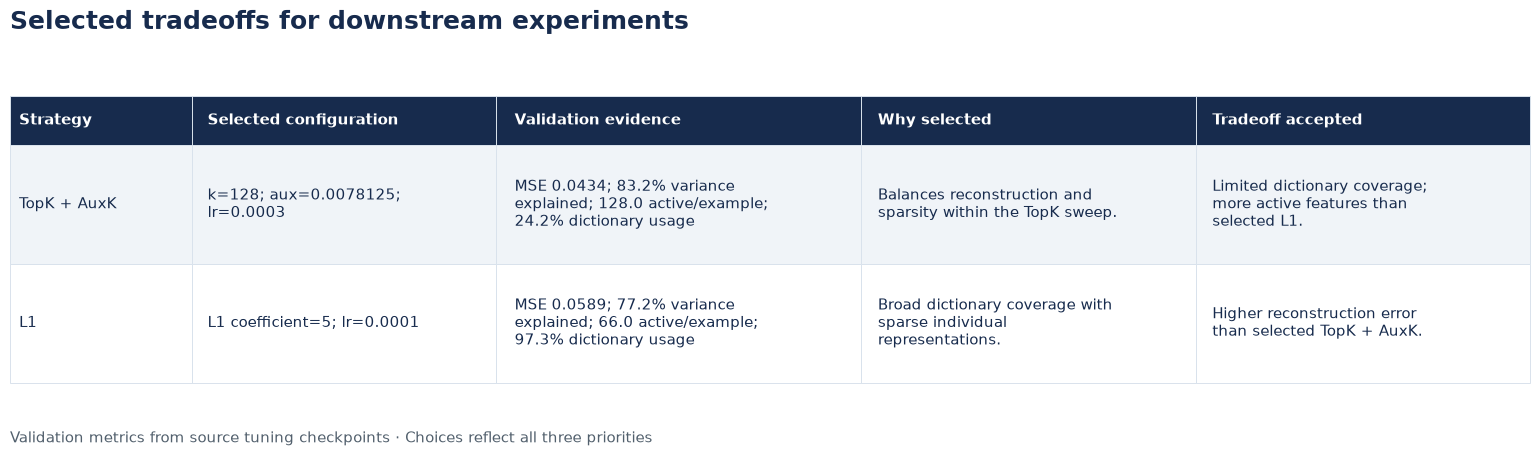

In [6]:
import textwrap

rationales = {
    "TopK + AuxK": (
        "Balances reconstruction and sparsity within the TopK sweep.",
        "Limited dictionary coverage; more active features than selected L1.",
    ),
    "L1": (
        "Broad dictionary coverage with sparse individual representations.",
        "Higher reconstruction error than selected TopK + AuxK.",
    ),
}
selection_rows = []
for label in RUN_IDS:
    row = sweep_trials.loc[sweep_trials["selected_model"].eq(label)].iloc[0]
    configuration = (
        f"k={int(row['top_k'])}; aux={row['aux_coefficient']:g}; lr={row['lr']:g}"
        if row["strategy"] == "TopK" else
        f"L1 coefficient={row['sparsity_coefficient']:g}; lr={row['lr']:g}"
    )
    selection_rows.append({
        "Strategy": label,
        "Selected configuration": configuration,
        "Validation evidence": (
            f"MSE {row['reconstruction_mse']:.4f}; "
            f"{row['variance_explained_pct']:.1f}% variance explained; "
            f"{row['mean_active_features']:.1f} active/example; "
            f"{row['dictionary_usage_pct']:.1f}% dictionary usage"
        ),
        "Why selected": rationales[label][0],
        "Tradeoff accepted": rationales[label][1],
    })
selection_rationale = pd.DataFrame(selection_rows)
display(selection_rationale)
selection_rationale.to_csv(TABLE_DIR / "sae_selection_rationale.csv", index=False)

with plt.rc_context({"svg.fonttype": "none", "font.family": "DejaVu Sans"}):
    fig, ax = plt.subplots(figsize=(16, 4.6))
    ax.axis("off")
    wrapped_rows = [
        [textwrap.fill(str(value), width=width) for value, width in zip(row, [14, 27, 32, 31, 30])]
        for row in selection_rationale.itertuples(index=False, name=None)
    ]
    table = ax.table(
        cellText=wrapped_rows, colLabels=selection_rationale.columns,
        colWidths=[0.12, 0.20, 0.24, 0.22, 0.22],
        cellLoc="left", bbox=[0, 0.08, 1, 0.83],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10.5)
    for (row, column), cell in table.get_celld().items():
        cell.set_edgecolor("#D9E2EC")
        cell.set_linewidth(0.7)
        cell.PAD = 0.05
        cell.set_height(0.14 if row == 0 else 0.34)
        cell.set_facecolor("#172B4D" if row == 0 else ("#F0F4F8" if row % 2 else "white"))
        cell.set_text_props(color="white" if row == 0 else "#172B4D",
                            weight="bold" if row == 0 else "normal", ha="left")
    fig.suptitle("Selected tradeoffs for downstream experiments", x=0.03, ha="left",
                 fontsize=18, fontweight="bold", color="#172B4D")
    fig.text(0.03, 0.04, "Validation metrics from source tuning checkpoints · Choices reflect all three priorities",
             fontsize=11, color="#52606D")
    fig.subplots_adjust(left=0.03, right=0.98, top=0.86, bottom=0.11)
    for extension in ("svg", "png"):
        fig.savefig(FIGURE_DIR / f"sae_selection_rationale.{extension}",
                    dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


## Presentation view: choosing one model from each strategy

This simpler figure focuses on the **two final sweeps used to choose the models**: eight TopK + AuxK trials and eight L1 refinement trials. Each panel includes every trial from its named study. The earlier 43-trial figure provides the broader search history.

**How to read it:**

- **Left panel:** TopK + AuxK. **Right panel:** L1.
- **Farther left:** a smaller percentage of the dictionary active on an average example (sparser).
- **Higher:** more validation variance explained (better reconstruction).
- **Brighter color:** more dictionary features active at least once on validation.
- **Black ring:** the source trial of the selected model.

**X-axis calculation:** `100 × mean_active_features / latent_dim`, using the saved dictionary size of 12,888 features. The selected TopK model uses about **0.99%** per example; the selected L1 model uses about **0.51%**. This per-example activity differs from dictionary usage across the entire validation split, shown by color.

Both panels show Y-axis values from **0 to 100% variance explained**, making the reconstruction differences visible on the full percentage range.

Both panels use the **same linear axes and the same 0–100% color scale**, so positions and colors can be compared directly. Each point is a saved best validation checkpoint. These are exploratory results from one seed, with a maximum of 200 epochs and early stopping.

**Decision to explain on the slide:**

- **TopK + AuxK:** chose `k=128` and auxiliary coefficient `0.0078125` to balance reconstruction and sparsity. Larger values of `k` reconstruct better but activate more features per example.
- **L1:** chose penalty `5` and learning rate `0.0001` for broad dictionary usage with sparse individual representations. Smaller penalties reconstruct better but activate more features. The other trial with penalty `5` uses fewer features per example, but covers less of the dictionary.

These are selected tradeoffs across our three priorities. Dictionary usage here means active at least once on validation; it does not establish feature interpretability or causal usefulness.

Run the earlier loading cells first to create `sweep_trials` and `REPO_ROOT`. The cell below saves an editable SVG to `reports/figures/sae_preliminary_results/sae_strategy_selection.svg`.


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import PercentFormatter

# Use all eight trials in each final sweep, with explicit study IDs.
PRESENTATION_STUDIES = {
    "TopK + AuxK": "20261013T173330494845Z-e5943205b957",
    "L1": "20261014T131200337301Z-edfc89a42125",
}
presentation_trials = sweep_trials.loc[
    sweep_trials["study_id"].isin(PRESENTATION_STUDIES.values())
].copy()
# Convert counts using the saved models' validated dictionary size.
dictionary_sizes = {run["config"]["latent_dim"] for run in runs.values()}
if len(dictionary_sizes) != 1:
    raise ValueError("The selected models must share a dictionary size.")
dictionary_size = dictionary_sizes.pop()
if dictionary_size <= 0:
    raise ValueError("Dictionary size must be positive.")
presentation_trials["mean_active_features_pct"] = (
    100 * presentation_trials["mean_active_features"] / dictionary_size
)

for label, study_id in PRESENTATION_STUDIES.items():
    subset = presentation_trials.loc[presentation_trials["study_id"].eq(study_id)]
    if len(subset) != 8 or subset["trial_id"].nunique() != 8:
        raise ValueError(f"Expected eight distinct trials for {label}.")
    if subset["selected_model"].eq(label).sum() != 1:
        raise ValueError(f"Expected one selected source trial for {label}.")

presentation_figure_dir = REPO_ROOT / "reports/figures/sae_preliminary_results"
presentation_figure_dir.mkdir(parents=True, exist_ok=True)
strategy_svg_path = presentation_figure_dir / "sae_strategy_selection.svg"

with plt.rc_context({"svg.fonttype": "none", "font.family": "DejaVu Sans", "font.size": 12}):
    strategy_fig, strategy_axes = plt.subplots(
        1, 2, figsize=(13, 6.5), sharex=True, sharey=True,
    )
    strategy_fig.subplots_adjust(left=0.08, right=0.87, bottom=0.23, top=0.79, wspace=0.12)
    usage_scale = Normalize(vmin=0, vmax=100)
    for ax, (label, study_id) in zip(strategy_axes, PRESENTATION_STUDIES.items()):
        subset = presentation_trials.loc[presentation_trials["study_id"].eq(study_id)]
        selected = subset.loc[subset["selected_model"].eq(label)].iloc[0]
        ax.scatter(
            subset["mean_active_features_pct"], subset["variance_explained_pct"],
            c=subset["dictionary_usage_pct"], cmap="viridis", norm=usage_scale,
            s=130, edgecolors="#475569", linewidths=0.7, zorder=3,
        )
        ax.scatter(
            selected["mean_active_features_pct"], selected["variance_explained_pct"],
            s=310, facecolors="none", edgecolors="black", linewidths=2, zorder=4,
        )
        settings = (
            f"k={int(selected['top_k'])}, aux={selected['aux_coefficient']:g}"
            if label == "TopK + AuxK" else
            f"Penalty={selected['sparsity_coefficient']:g}, lr={selected['lr']:g}"
        )
        selected_label = (
            f"Selected: {settings}\n"
            f"{selected['mean_active_features_pct']:.2f}% active per example\n"
            f"{selected['variance_explained_pct']:.1f}% variance explained\n"
            f"{selected['dictionary_usage_pct']:.1f}% dictionary usage"
        )
        # ax.annotate(
        #     selected_label,
        #     xy=(selected["mean_active_features_pct"], selected["variance_explained_pct"]),
        #     xytext=(0.31, 0.13) if label == "TopK + AuxK" else (0.13, 0.70),
        #     textcoords="axes fraction", ha="left", va="bottom", fontsize=10.5,
        #     bbox={"boxstyle": "round,pad=0.5", "fc": "white", "ec": "#CBD5E1"},
        #     arrowprops={"arrowstyle": "-", "color": "#334155", "lw": 1.2},
        #     zorder=5,
        # )
        ax.set_title(f"{label} · 8 trials", loc="left", fontsize=15, fontweight="bold", pad=14)
        ax.set_xlim(0, 4.3)
        ax.set_ylim(0, 100)
        ax.set_xticks([0, 1, 2, 3, 4])
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        ax.set_yticks([0, 20, 40, 60, 80, 100])
        ax.tick_params(axis="y", labelleft=True)
        ax.set_xlabel("Average dictionary active per example (%)\n← Sparser", labelpad=10)
        ax.grid(alpha=0.18, zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
    strategy_axes[0].set_ylabel("Validation variance explained (%)\nHigher is better", labelpad=10)
    color_axis = strategy_fig.add_axes([0.90, 0.25, 0.017, 0.50])
    colorbar = strategy_fig.colorbar(
        ScalarMappable(norm=usage_scale, cmap="viridis"), cax=color_axis,
        ticks=[0, 25, 50, 75, 100],
    )
    colorbar.set_label("Dictionary usage on validation (%)", labelpad=12)
    strategy_fig.suptitle("Choosing a tradeoff for each sparsity strategy", fontsize=19,
                          fontweight="bold", x=0.08, ha="left", y=0.95)
    strategy_fig.text(0.08, 0.875, "Final sweeps · One point per trial · Selected models circled",
                      fontsize=12, color="#475569")
    strategy_fig.text(
        0.08, 0.065,
        "Per-example activity = mean active features / dictionary size. Color = active at least once on validation.\n"
        "Source tuning checkpoints · Seed 42 · Maximum 200 epochs · Full search shown above",
        fontsize=10, color="#475569",
    )
    strategy_fig.savefig(strategy_svg_path, format="svg", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(strategy_fig)

print(f"Saved SVG: {strategy_svg_path.relative_to(REPO_ROOT)}")
